# ARTI403 – Image Processing | Lab 6: Frequency Domain

**Student name:**Hussain Alhashem  **ID:** 2240006192
This notebook contains:
1. **Task 1 (from the manual):** Laplacian filtering in the frequency domain.
2. **Assessment Task 1:** Sobel filtering (X and Y) in the frequency domain on the Cameraman image.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, fftshift, ifftshift
from skimage import data
from skimage.transform import resize
from scipy.signal import convolve2d

## Task 1 (Manual): Laplacian Filter in the Frequency Domain

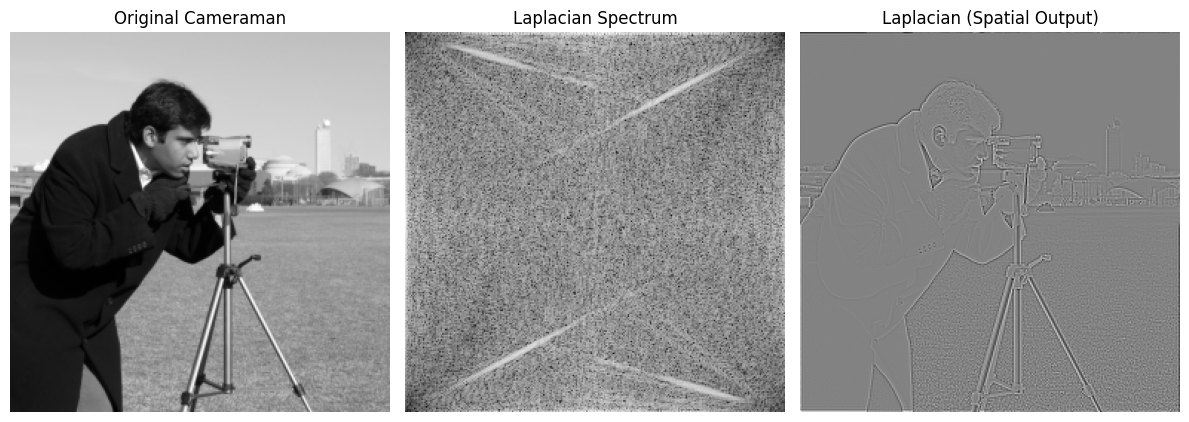

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT

M, N = image.shape

# Centered frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray'); plt.title('Laplacian Spectrum'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(laplacian_image, cmap='gray'); plt.title('Laplacian (Spatial Output)'); plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 1: Sobel Filters in the Frequency Domain

**Idea:** By the convolution theorem, spatial convolution equals multiplication in the frequency domain:

$$g(x,y) = f(x,y) * h(x,y) \;\Longleftrightarrow\; G(u,v) = F(u,v)\,H(u,v)$$

Steps:
1. Load and resize the image, compute its FFT.
2. Embed each 3×3 Sobel kernel in a zero array the size of the image, centered, then `ifftshift` so the kernel center sits at (0,0), and take its FFT.
3. Multiply the image FFT by each kernel FFT.
4. Inverse FFT to get the filtered images, then combine the gradient magnitude.

### Step 1: Load and resize image

In [3]:
image = data.camera()
image = resize(image, (256, 256))   # float in [0, 1]
M, N = image.shape
print("Image shape:", image.shape)

Image shape: (256, 256)


### Step 2: Define the Sobel filters

In [4]:
# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

### Step 3: Pad and center the kernel, then take its FFT

In [5]:
# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape

    # Find center coordinates
    cy, cx = ph // 2, pw // 2

    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel

    # Shift before FFT to place (0,0) at top-left
    return fft2(ifftshift(padded))

### Step 4: Compute FFT of the image and of the Sobel filters

In [6]:
# FFT of the image
F = fft2(image)

# FFT of centered Sobel filters
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

### Step 5: Multiply in the frequency domain and go back to the spatial domain

In [7]:
# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y

# Inverse FFT (result is real up to numerical error)
sobel_x_img = ifft2(G_x).real
sobel_y_img = ifft2(G_y).real

# Gradient magnitude
sobel_mag = np.sqrt(sobel_x_img**2 + sobel_y_img**2)

### Step 6: Plot the results

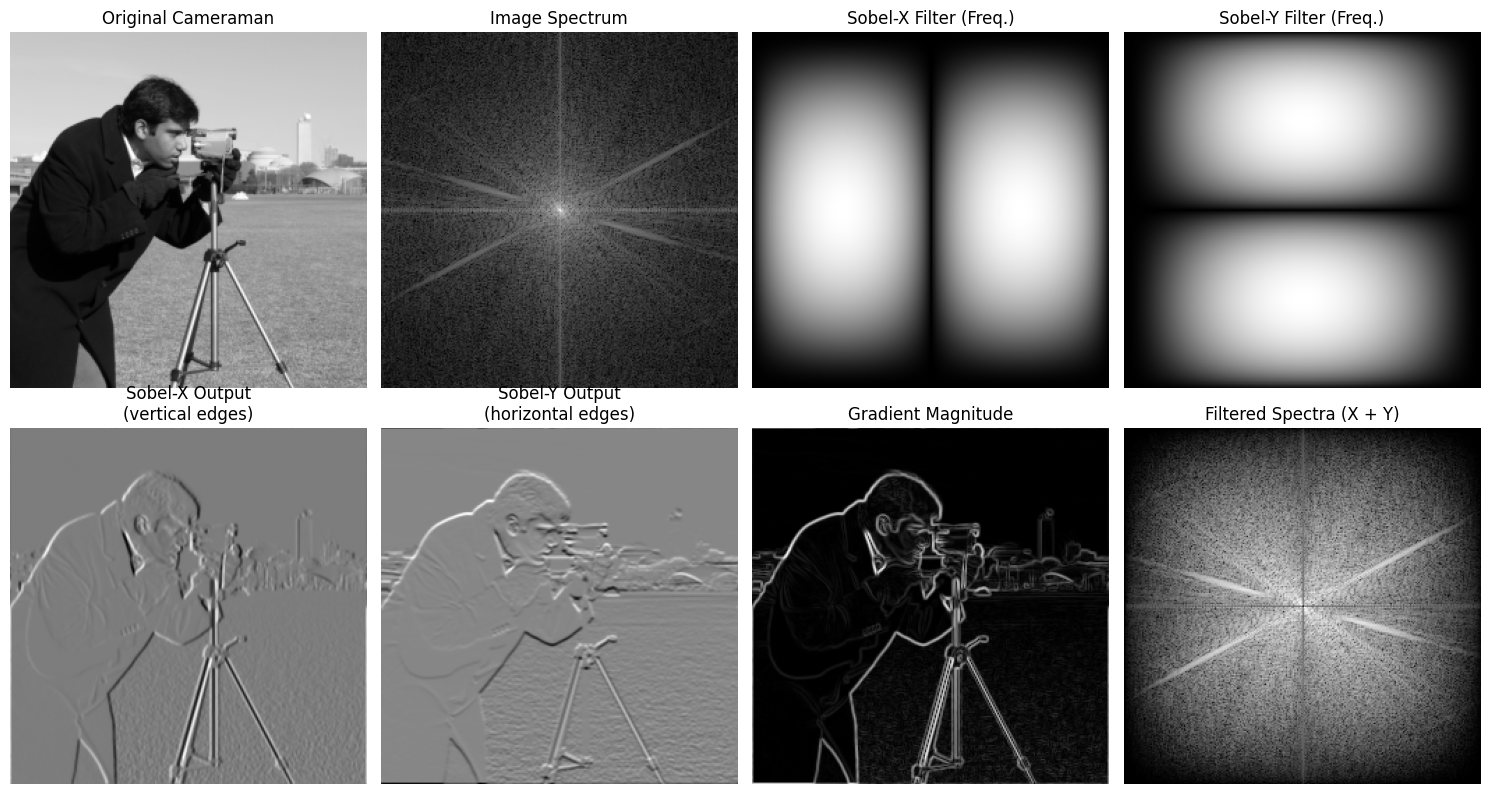

In [8]:
def spectrum(X):
    return np.log(1 + np.abs(fftshift(X)))

plt.figure(figsize=(15, 8))

plt.subplot(2, 4, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(2, 4, 2); plt.imshow(spectrum(F), cmap='gray'); plt.title('Image Spectrum'); plt.axis('off')
plt.subplot(2, 4, 3); plt.imshow(spectrum(H_x), cmap='gray'); plt.title('Sobel-X Filter (Freq.)'); plt.axis('off')
plt.subplot(2, 4, 4); plt.imshow(spectrum(H_y), cmap='gray'); plt.title('Sobel-Y Filter (Freq.)'); plt.axis('off')

plt.subplot(2, 4, 5); plt.imshow(sobel_x_img, cmap='gray'); plt.title('Sobel-X Output\n(vertical edges)'); plt.axis('off')
plt.subplot(2, 4, 6); plt.imshow(sobel_y_img, cmap='gray'); plt.title('Sobel-Y Output\n(horizontal edges)'); plt.axis('off')
plt.subplot(2, 4, 7); plt.imshow(sobel_mag, cmap='gray'); plt.title('Gradient Magnitude'); plt.axis('off')
plt.subplot(2, 4, 8); plt.imshow(spectrum(G_x) + spectrum(G_y), cmap='gray'); plt.title('Filtered Spectra (X + Y)'); plt.axis('off')

plt.tight_layout()
plt.show()

### Verification (optional): compare with spatial-domain Sobel

The frequency-domain result should match spatial **circular** convolution with the same kernel. Note: multiplying FFTs performs *convolution*, which flips the kernel, so the sign of the output is opposite to correlation-style Sobel (e.g. `cv2.Sobel`). The edge magnitude is identical.

Max |diff| Sobel-X : 1.7763568394002505e-15
Max |diff| Sobel-Y : 2.8622937353617317e-15
Max |diff| Magnitude: 2.6645352591003757e-15


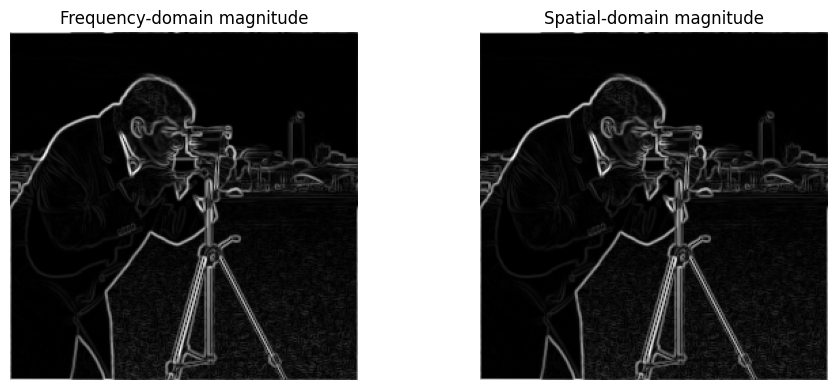

In [9]:
sx_spatial = convolve2d(image, sobel_x, mode='same', boundary='wrap')
sy_spatial = convolve2d(image, sobel_y, mode='same', boundary='wrap')
mag_spatial = np.sqrt(sx_spatial**2 + sy_spatial**2)

print("Max |diff| Sobel-X :", np.abs(sobel_x_img - sx_spatial).max())
print("Max |diff| Sobel-Y :", np.abs(sobel_y_img - sy_spatial).max())
print("Max |diff| Magnitude:", np.abs(sobel_mag - mag_spatial).max())

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(sobel_mag, cmap='gray'); plt.title('Frequency-domain magnitude'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(mag_spatial, cmap='gray'); plt.title('Spatial-domain magnitude'); plt.axis('off')
plt.tight_layout()
plt.show()

## Conclusion

- Sobel filtering was done in the frequency domain by multiplying the image FFT with the FFT of each centered, zero-padded Sobel kernel, then applying the inverse FFT.
- **Sobel-X** responds to vertical edges and **Sobel-Y** to horizontal edges; the **gradient magnitude** combines both and shows all edges.
- The filter spectra show that Sobel is a high-pass filter in one direction combined with smoothing (low-pass) in the perpendicular direction.
- The result matches spatial circular convolution (differences are on the order of 1e-15), confirming the convolution theorem. Because the FFT assumes periodic images, edges wrap around at the borders.